# Notebook 2 - Modèle MACRO : prévoir le nombre de sinistres par mois

**Question :** combien de sinistres la CNPS va-t-elle recevoir chaque mois, au niveau national et par secteur ?

**Choix de méthode (information métier) :** l'année **2026 est incomplète** à la date d'extraction. Plutôt que de mélanger des mois partiels avec le reste, on **coupe les données à fin 2025** (dernière année complète), on construit et valide les modèles sur ces années complètes, puis on **prévoit l'année civile 2026 entière**. On compare enfin cette prévision au **réel 2026 observé** (mois déjà complets), ce qui fournit une validation *hors échantillon* honnête.

**Étapes :**
1. construire la série mensuelle des sinistres (jusqu'à fin 2025) ;
2. l'analyser : tendance et saisonnalité ;
3. justifier et comparer trois modèles (test sur l'année 2025) ;
4. prévoir l'année 2026 et la confronter au réel observé.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import logging
import warnings
logging.getLogger("prophet.plot").disabled = True     # masque les messages techniques de Prophet
logging.getLogger("cmdstanpy").disabled = True
warnings.filterwarnings("ignore")

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
import os, glob
import prophet as _prophet
# Prophet (cmdstan) exige SA propre tbb.dll ; on la place en tete du PATH pour qu'une
# autre tbb.dll du systeme (OSGeo4W/QGIS, oneAPI...) ne la masque pas (erreur 0xC0000139).
_tbbdir = next((os.path.dirname(p) for p in glob.glob(os.path.join(os.path.dirname(_prophet.__file__), "**", "tbb.dll"), recursive=True)), None)
if _tbbdir:
    os.environ["PATH"] = _tbbdir + os.pathsep + os.environ.get("PATH", "")

from prophet import Prophet
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

sin = pd.read_parquet("data/sinistres_propre.parquet")

## 1. Construire la série mensuelle

On crée une date (le 1er du mois de l'accident), puis on compte les sinistres par mois.

In [2]:
sin = sin.dropna(subset=["ANNEE_ACCIDENT", "MOIS_ACCIDENT"])
sin["date"] = pd.to_datetime(dict(year=sin["ANNEE_ACCIDENT"], month=sin["MOIS_ACCIDENT"], day=1))

serie = sin.groupby("date").size()
serie = serie.asfreq("MS", fill_value=0)       # un point par mois, 0 si aucun sinistre

serie["2025-06":].to_frame("nb_sinistres").T

date,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
nb_sinistres,642,709,623,692,717,759,770,719,752,712,786,750,846,892,724,307


**Pourquoi couper à fin 2025 ?** Les derniers mois de l'extraction sont **incomplets** : l'extraction s'arrête en cours d'année 2026 et certains accidents sont déclarés plusieurs semaines après les faits (août et septembre 2026 sont déjà anormalement bas). Garder ces mois fausserait l'estimation de la tendance et de la saisonnalité.

On construit donc :
* `serie` : les sinistres mensuels de **janvier 2012 à décembre 2025** (années complètes) → sert à analyser, entraîner et valider ;
* `obs_2026` : le **réel 2026 observé** sur les mois déjà complets (jan.→juil. 2026) → servira uniquement à **vérifier** la prévision, jamais à l'entraîner.

On démarre en **2012**, après la crise 2009–2011 qui perturbe la série (cf. notebook 1).

Série d'étude : 01/2012 -> 12/2025  (168 mois)
Réel 2026 observé pour validation : 01/2026 -> 07/2026


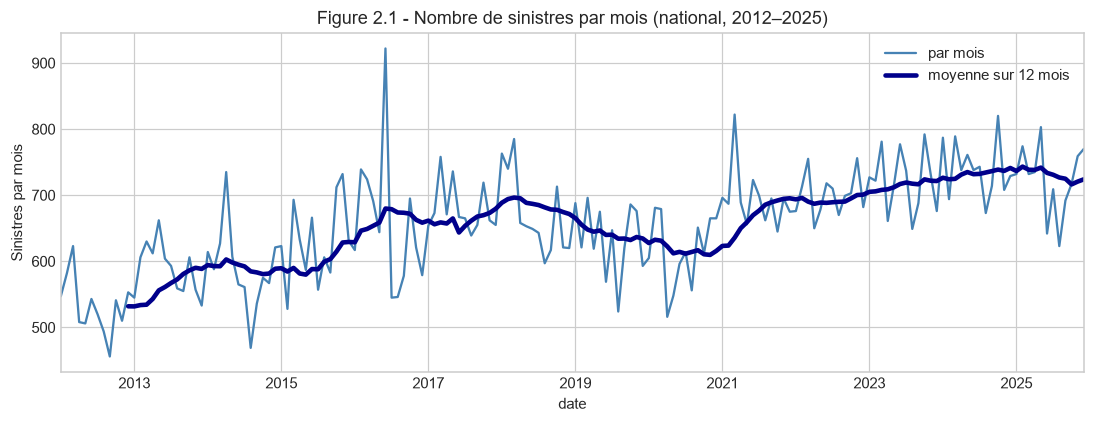

In [3]:
serie_complete = serie["2012-01":"2026-07"]     # jusqu'au dernier mois fiable
serie = serie_complete[:"2025-12"]              # années complètes : analyse + entraînement + validation
obs_2026 = serie_complete["2026-01":"2026-07"]  # réel 2026 observé (mois complets) : validation seulement

print(f"Série d'étude : {serie.index[0]:%m/%Y} -> {serie.index[-1]:%m/%Y}  ({len(serie)} mois)")
print(f"Réel 2026 observé pour validation : {obs_2026.index[0]:%m/%Y} -> {obs_2026.index[-1]:%m/%Y}")

serie.plot(figsize=(12, 4), color="steelblue")
serie.rolling(12).mean().plot(color="darkblue", linewidth=3, label="moyenne sur 12 mois")
plt.title("Figure 2.1 - Nombre de sinistres par mois (national, 2012–2025)")
plt.ylabel("Sinistres par mois")
plt.legend(["par mois", "moyenne sur 12 mois"])
plt.show()

**Commentaire - Figure 2.1 :** la série monte de ~550 sinistres par mois en 2012 à ~750 en 2025. On distingue :
* une **tendance à la hausse** (courbe épaisse) ;
* un **creux en 2019–2020** (COVID-19) ;
* des **variations d'un mois à l'autre** de ± 50 à 100 sinistres.

Deux composantes à modéliser ressortent : une **tendance** et une **saisonnalité annuelle**. C'est ce que confirme la décomposition ci-dessous.

## 2. Tendance et saisonnalité

La **décomposition** sépare la série en trois parties : tendance + saisonnalité + bruit.

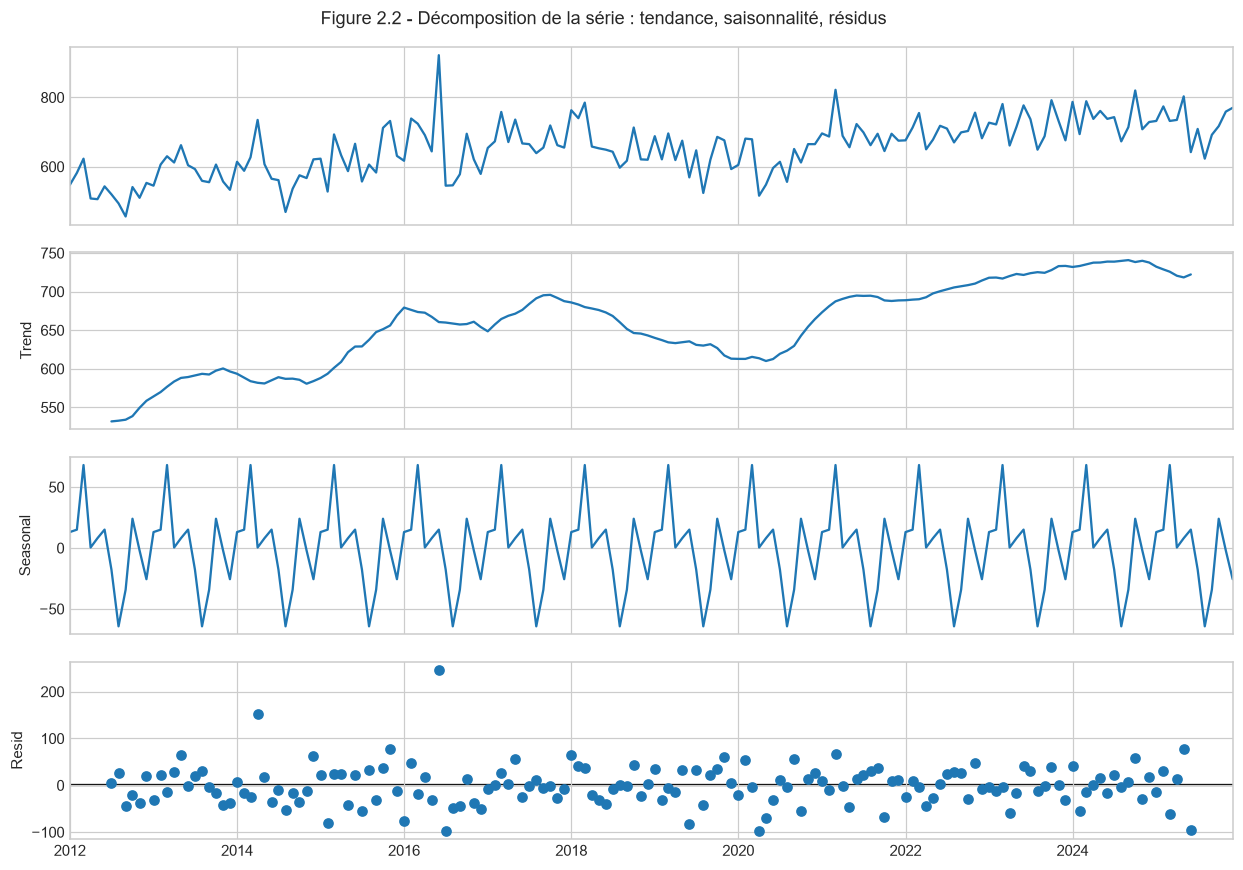

In [4]:
decomposition = seasonal_decompose(serie, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Figure 2.2 - Décomposition de la série : tendance, saisonnalité, résidus", y=1.01)
plt.show()

**Commentaire - Figure 2.2 :**
* **Tendance (2e graphique) :** elle passe d'environ 530 à 740 sinistres par mois entre 2012 et 2025, avec une baisse en 2018–2020.
* **Saisonnalité (3e graphique) :** le même motif se répète chaque année, avec une amplitude d'environ ± 60 sinistres. Elle est donc **réelle mais modérée** par rapport au niveau (~700).
* **Résidus (4e graphique) :** ils sont centrés sur 0, avec quelques mois exceptionnels (mi-2016 par exemple).

➡️ Il faut un modèle qui gère **à la fois la tendance et la saisonnalité** de 12 mois : c'est le cas de SARIMA et de Prophet.

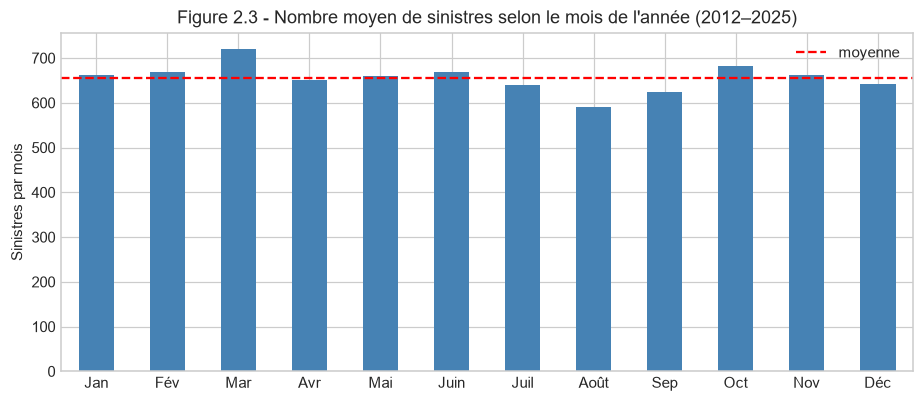

In [5]:
noms_mois = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
moyenne_par_mois = serie.groupby(serie.index.month).mean()
moyenne_par_mois.index = noms_mois

moyenne_par_mois.plot(kind="bar", figsize=(10, 4), color="steelblue", rot=0)
plt.axhline(moyenne_par_mois.mean(), color="red", linestyle="--", label="moyenne")
plt.title("Figure 2.3 - Nombre moyen de sinistres selon le mois de l'année (2012–2025)")
plt.ylabel("Sinistres par mois")
plt.legend()
plt.show()

**Commentaire - Figure 2.3 :** **mars** est le mois le plus chargé (~720 sinistres) ; **août et septembre** les plus calmes (~590–625), ce qui correspond aux congés et au ralentissement de l'activité. L'écart entre le mois le plus chargé et le plus calme est d'environ **20 %** - utile pour **planifier les effectifs**.

## 3. Quel modèle, et pourquoi ? Comparaison sur l'année 2025

### 3.0 Pourquoi SARIMA plutôt qu'un autre modèle ?

La série a trois caractéristiques qui **dictent la famille de modèle** : (a) une **tendance** lente, (b) une **saisonnalité de 12 mois stable**, (c) une longueur **modérée** (~168 points mensuels). On confronte les candidats à ces contraintes :

| Candidat | Adapté ? | Raison |
|---|---|---|
| **Moyenne / naïf saisonnier** | référence | ne s'adapte pas à la tendance ; sert de **garde-fou** à battre |
| **Lissage exponentiel (Holt-Winters)** | possible | gère tendance + saison, mais **pas d'intervalle de confiance analytique** aussi propre ; c'est un **cas particulier** de SARIMA |
| **Prophet** | possible | souple, mais **extrapole agressivement la tendance** sur séries courtes → risque de dérapage (confirmé plus loin sur le transport : +30 %) |
| **Réseaux de neurones (LSTM)** | non | demandent des **milliers** de points ; avec 168 mois, ils **sur-apprennent** |
| **SARIMA (Box-Jenkins)** | **retenu** | **référence** pour une série mensuelle tendance + saison de longueur modérée ; fournit un **intervalle de confiance analytique** (indispensable pour budgéter) ; **robuste** (jamais d'erreur catastrophique dans nos tests) |

Au-delà de « ça marche », SARIMA est donc le choix **le plus approprié par construction**. On le confirme ensuite par trois diagnostics statistiques, puis par la comparaison chiffrée.

**Protocole de validation :** on **cache l'année 2025** (les 12 derniers mois). Les modèles s'entraînent sur 2012→2024, puis on compare leurs prévisions de 2025 à la réalité. Métriques : **MAE** (erreur moyenne en sinistres), **MAPE** (en %), **écart annuel** (sur le total des 12 mois).

### 3.1 Diagnostic statistique de la spécification SARIMA

Trois vérifications objectives justifient le choix d'un SARIMA(1,1,1)(1,1,1)₁₂ :
1. **Stationnarité (test ADF)** : la série brute n'est pas stationnaire (tendance) ; une différenciation simple puis saisonnière la rend stationnaire → cela justifie les ordres de différenciation *d=1* et *D=1*.
2. **Apport de la saisonnalité (AIC)** : le SARIMA saisonnier doit avoir un **AIC nettement plus bas** qu'un ARIMA sans saison.
3. **Résidus = bruit blanc (test de Ljung-Box)** : si le modèle a bien capté la structure, il ne doit **rien rester** dans les résidus (p-value > 0,05).

In [6]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. Stationnarité (ADF) : H0 = série non stationnaire
for nom, s in [("série brute", serie),
               ("diff. simple (1)", serie.diff().dropna()),
               ("diff. simple + saison. (12)", serie.diff().diff(12).dropna())]:
    p = adfuller(s)[1]
    print(f"ADF {nom:30s} p = {p:.3f} -> {'stationnaire' if p < 0.05 else 'NON stationnaire'}")

# 2. Apport de la saisonnalité : AIC
m_saison = SARIMAX(serie, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
m_sans = SARIMAX(serie, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0)).fit(disp=False)
print(f"\nAIC SARIMA saisonnier = {m_saison.aic:.0f}   vs   ARIMA sans saison = {m_sans.aic:.0f}"
      f"   -> {'saison utile' if m_saison.aic < m_sans.aic else 'saison inutile'}")

# 3. Résidus = bruit blanc ? (Ljung-Box, H0 = pas d'autocorrélation résiduelle)
p_lb = acorr_ljungbox(m_saison.resid[13:], lags=[12], return_df=True)["lb_pvalue"].iloc[0]
print(f"Ljung-Box (lag 12) p = {p_lb:.3f} -> "
      f"{'résidus = bruit blanc (modèle adéquat)' if p_lb > 0.05 else 'structure résiduelle restante'}")

ADF série brute                    p = 0.316 -> NON stationnaire
ADF diff. simple (1)               p = 0.002 -> stationnaire
ADF diff. simple + saison. (12)    p = 0.000 -> stationnaire



AIC SARIMA saisonnier = 1694   vs   ARIMA sans saison = 1846   -> saison utile
Ljung-Box (lag 12) p = 0.740 -> résidus = bruit blanc (modèle adéquat)


**Lecture du diagnostic :** la série devient stationnaire après différenciation (ADF), l'AIC chute quand on ajoute la composante saisonnière (elle est donc utile), et les résidus se comportent comme du **bruit blanc**. La spécification SARIMA est donc **statistiquement validée**, pas seulement choisie par habitude.

In [7]:
def comparer_modeles(serie, nom):
    train = serie[:-12]
    test = serie[-12:]

    # 1. Naïf saisonnier
    pred_naif = pd.Series(train[-12:].values, index=test.index)

    # 2. SARIMA
    sarima = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
    pred_sarima = sarima.forecast(12)

    # 3. Prophet
    prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    prophet.fit(pd.DataFrame({"ds": train.index, "y": train.values}))
    pred_prophet = prophet.predict(pd.DataFrame({"ds": test.index}))["yhat"]
    pred_prophet.index = test.index

    predictions = {"Naïf saisonnier": pred_naif, "SARIMA": pred_sarima, "Prophet": pred_prophet}

    # Tableau des erreurs
    resultats = []
    for modele, pred in predictions.items():
        resultats.append({
            "Modèle": modele,
            "MAE": np.mean(np.abs(test - pred)),
            "MAPE (%)": np.mean(np.abs(test - pred) / test) * 100,
            "Écart annuel (%)": (pred.sum() - test.sum()) / test.sum() * 100,
        })
    resultats = pd.DataFrame(resultats).set_index("Modèle").round(1)

    # Graphique
    plt.figure(figsize=(12, 4.5))
    plt.plot(train["2023":], color="black", label="historique")
    plt.plot(test, color="black", marker="o", linewidth=2.5, label="réalité 2025 (cachée au modèle)")
    plt.plot(pred_naif, "--", color="grey", label="Naïf saisonnier")
    plt.plot(pred_sarima, "--", color="tab:blue", label="SARIMA")
    plt.plot(pred_prophet, "--", color="tab:orange", label="Prophet")
    plt.title(f"{nom} : prévisions des 12 derniers mois vs réalité")
    plt.ylabel("Sinistres par mois")
    plt.legend()
    plt.show()

    return resultats

### 3.2 Niveau national (Figure 2.4) - test sur l'année 2025

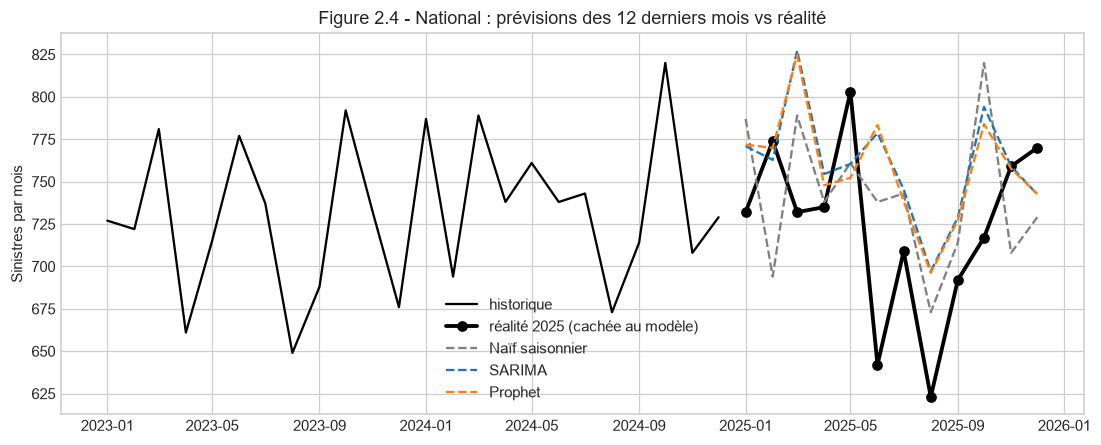

,MAE,MAPE (%),Écart annuel (%)
Modèle,,,
Naïf saisonnier,52.8,7.4,2.4
SARIMA,49.7,7.1,5.0
Prophet,47.9,6.9,4.7


In [8]:
comparer_modeles(serie, "Figure 2.4 - National")

**Commentaire - Figure 2.4 (national) :**
* **SARIMA** et **Prophet** battent la référence naïve : voir la colonne MAPE du tableau ci-dessus (erreur moyenne en % sur les 12 mois de 2025).
* Sur le **total annuel** (colonne « Écart annuel »), l'erreur reste de quelques pour cent : suffisant pour **planifier un budget ou des effectifs**.
* L'écart de performance entre SARIMA et Prophet est faible au national ; c'est leur **robustesse** sur les petits secteurs (section 5) qui départagera.

### 3.3 Secteur du BTP (Figure 2.5)

### 3.4 Comment sont calculées les métriques ? (exemple : SARIMA, niveau national, test 2025)

Pour chacun des 12 mois cachés de 2025, on compare le **réel** et le **prévu** :

| Métrique | Formule | Lecture |
|---|---|---|
| **Erreur** | réel − prévu | positive = **sous-estimé** ; négative = **surestimé** |
| **MAE** | moyenne de \|réel − prévu\| | « en moyenne, on se trompe de X sinistres par mois » |
| **RMSE** | √ moyenne de (réel − prévu)² | comme la MAE, mais **pénalise les grosses erreurs** |
| **MAPE** | moyenne de \|réel − prévu\| / réel × 100 | erreur en % ; comparable entre séries |
| **Écart annuel** | (total prévu − total réel) / total réel × 100 | erreur sur le **total** : utile pour le budget |

Le tableau ci-dessous détaille le calcul mois par mois.

In [9]:
train, test = serie[:-12], serie[-12:]
prevu = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False).forecast(12)

calcul = pd.DataFrame({"réel": test, "prévu": prevu.round(1)})
calcul["erreur"] = calcul["réel"] - calcul["prévu"]
calcul["|erreur|"] = calcul["erreur"].abs()
calcul["erreur²"] = calcul["erreur"] ** 2
calcul["|erreur| en %"] = (calcul["|erreur|"] / calcul["réel"] * 100).round(1)
calcul.index = calcul.index.strftime("%m/%Y")

print(f"MAE  = moyenne de |erreur|           = {calcul['|erreur|'].mean():.1f} sinistres")
print(f"RMSE = racine(moyenne de erreur²)    = {np.sqrt(calcul['erreur²'].mean()):.1f} sinistres")
print(f"MAPE = moyenne de |erreur| en %      = {calcul['|erreur| en %'].mean():.1f} %")
print(f"Écart annuel = (prévu − réel) / réel = {(calcul['prévu'].sum() - calcul['réel'].sum()) / calcul['réel'].sum() * 100:.1f} %")
calcul.round(1)

MAE  = moyenne de |erreur|           = 49.7 sinistres
RMSE = racine(moyenne de erreur²)    = 62.2 sinistres
MAPE = moyenne de |erreur| en %      = 7.1 %
Écart annuel = (prévu − réel) / réel = 5.0 %


,réel,prévu,erreur,|erreur|,erreur²,|erreur| en %
01/2025,732,770.9,-38.9,38.9,1513.2,5.3
02/2025,774,762.8,11.2,11.2,125.4,1.4
03/2025,732,827.3,-95.3,95.3,9082.1,13.0
04/2025,735,754.5,-19.5,19.5,380.2,2.7
05/2025,803,760.5,42.5,42.5,1806.2,5.3
06/2025,642,778.6,-136.6,136.6,18659.6,21.3
07/2025,709,745.5,-36.5,36.5,1332.2,5.1
08/2025,623,697.2,-74.2,74.2,5505.6,11.9
09/2025,692,728.9,-36.9,36.9,1361.6,5.3
10/2025,717,794.1,-77.1,77.1,5944.4,10.8


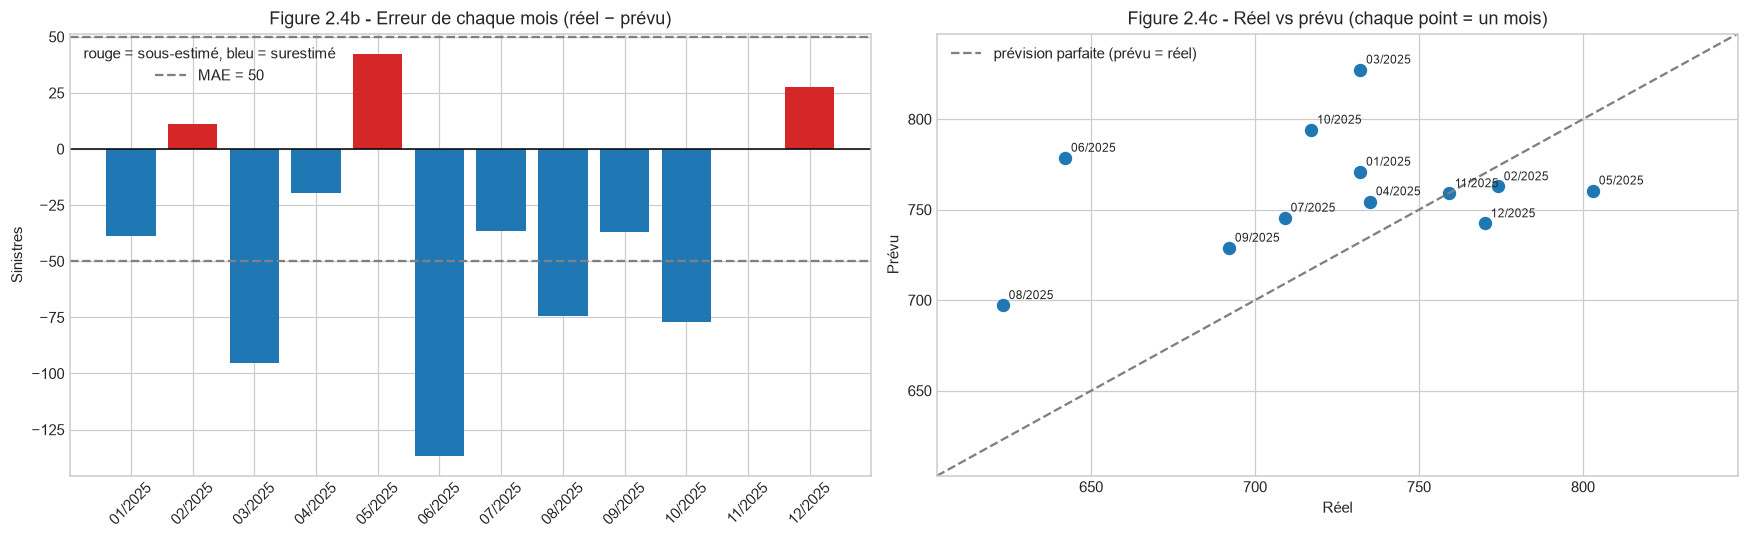

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Erreur de chaque mois
couleurs = ["tab:red" if e > 0 else "tab:blue" for e in calcul["erreur"]]
axes[0].bar(calcul.index, calcul["erreur"], color=couleurs)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].axhline(calcul["|erreur|"].mean(), color="grey", linestyle="--", label=f"MAE = {calcul['|erreur|'].mean():.0f}")
axes[0].axhline(-calcul["|erreur|"].mean(), color="grey", linestyle="--")
axes[0].set_title("Figure 2.4b - Erreur de chaque mois (réel − prévu)")
axes[0].set_ylabel("Sinistres")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="rouge = sous-estimé, bleu = surestimé")

# Réel vs prévu
axes[1].scatter(calcul["réel"], calcul["prévu"], s=60, color="tab:blue")
mini, maxi = calcul[["réel", "prévu"]].min().min() - 20, calcul[["réel", "prévu"]].max().max() + 20
axes[1].plot([mini, maxi], [mini, maxi], "--", color="grey", label="prévision parfaite (prévu = réel)")
for mois, ligne in calcul.iterrows():
    axes[1].annotate(mois, (ligne["réel"], ligne["prévu"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_xlim(mini, maxi)
axes[1].set_ylim(mini, maxi)
axes[1].set_title("Figure 2.4c - Réel vs prévu (chaque point = un mois)")
axes[1].set_xlabel("Réel")
axes[1].set_ylabel("Prévu")
axes[1].legend()

plt.tight_layout()
plt.show()

**Commentaire - Tableau et Figures 2.4b / 2.4c :**
* L'erreur de chaque mois reste **modérée** : la plupart des points de la Figure 2.4c sont proches de la diagonale « prévu = réel ».
* L'écart entre **MAE** et **RMSE** indique s'il existe **quelques mois très mal prévus** : plus l'écart est grand, plus une ou deux valeurs extrêmes pèsent.
* **À retenir pour l'oral :** la MAE dit « de combien on se trompe en moyenne » ; le RMSE dit « y a-t-il de grosses erreurs isolées ».

Nombre moyen de sinistres BTP par mois : 46


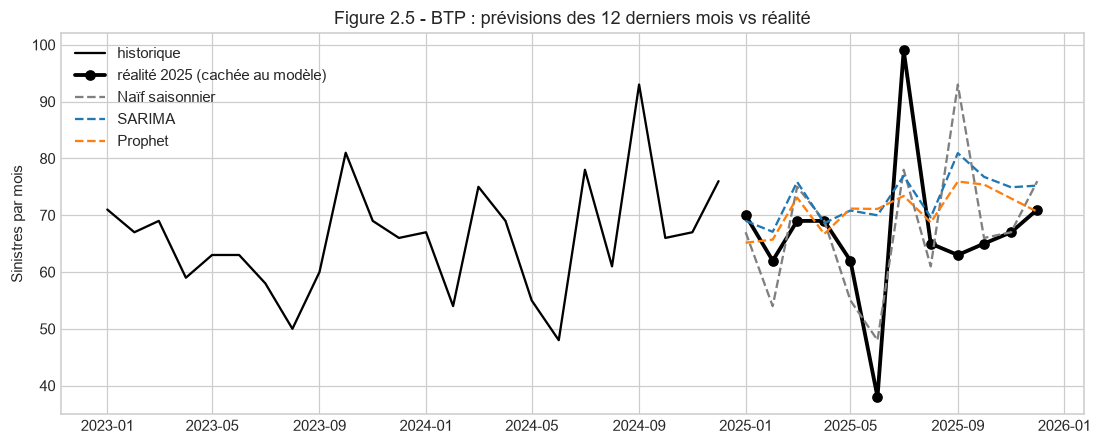

,MAE,MAPE (%),Écart annuel (%)
Modèle,,,
Naïf saisonnier,7.9,12.3,1.1
SARIMA,10.2,17.7,9.5
Prophet,9.7,16.8,6.2


In [11]:
btp = sin[sin["SECTEUR_ACTIVITE"] == "BATIMENT ET T.P"]
serie_btp_complete = btp.groupby("date").size().asfreq("MS", fill_value=0)["2012-01":"2026-07"]
serie_btp = serie_btp_complete[:"2025-12"]              # entraînement + validation
obs_btp = serie_btp_complete["2026-01":"2026-07"]       # réel 2026 observé
print("Nombre moyen de sinistres BTP par mois :", round(serie_btp.mean()))

comparer_modeles(serie_btp, "Figure 2.5 - BTP")

**Commentaire - Figure 2.5 (BTP) :** l'erreur est **plus grande** (MAPE autour de 14–17 %). Ce n'est pas un défaut des modèles : avec seulement **~47 sinistres par mois**, le **hasard** pèse beaucoup. Pour un phénomène de Poisson de ce volume, la variation naturelle est d'environ 1/√47 ≈ **15 %** par mois. Les modèles sont donc **proches de la meilleure précision possible**.

➡️ Pour un petit secteur, mieux vaut raisonner sur des **totaux trimestriels ou annuels** que mois par mois.

## 4. Prévision de l'année 2026 et validation sur le réel observé

On ré-entraîne SARIMA sur **toutes les données jusqu'à fin 2025**, puis on prévoit les **12 mois de 2026** avec un **intervalle de confiance à 95 %**. On superpose le **réel 2026 déjà observé** (jan.→juil.) : c'est une validation *hors échantillon*, puisque ces mois n'ont jamais servi à l'entraînement.

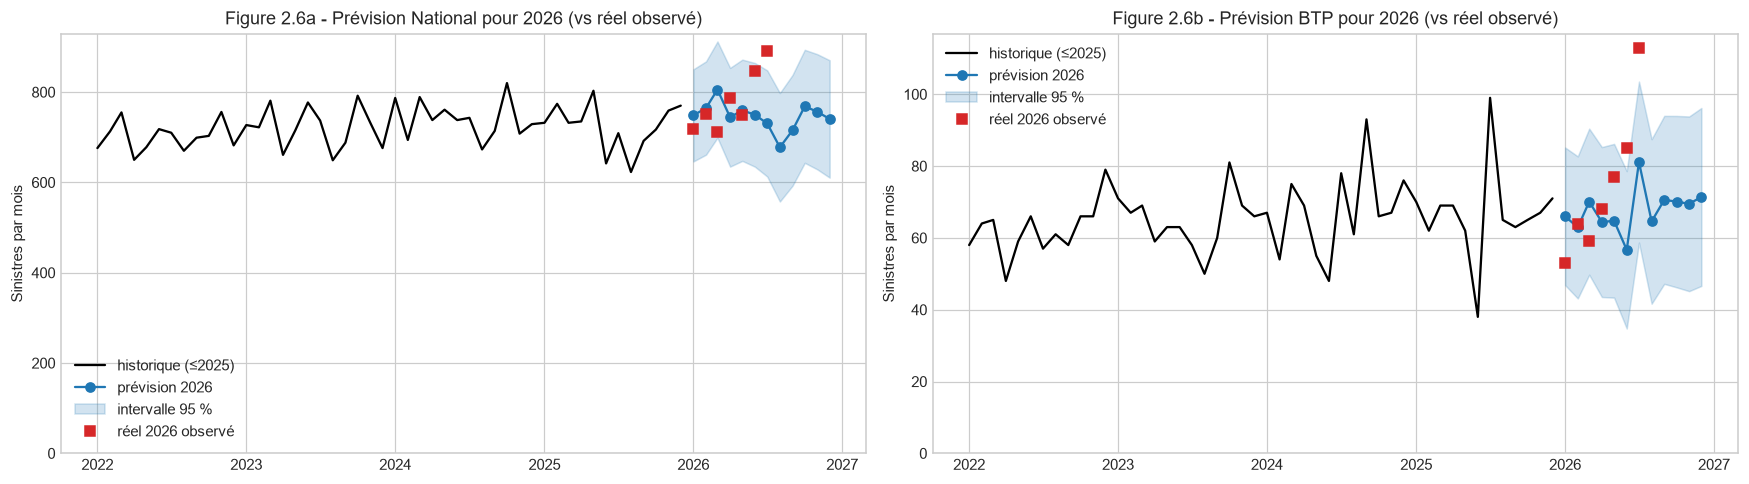

Validation : erreur de la prévision 2026 sur les mois déjà observés (jan.→juil. 2026)


,Réel 2025,Prévu 2026,MAPE validation 2026 (%)
National,8688.0,8961.0,7.9
BTP,800.0,812.0,18.2


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
totaux = {}
modeles_finaux = {}

for ax, (s, obs, nom, lettre) in zip(axes, [(serie, obs_2026, "National", "a"), (serie_btp, obs_btp, "BTP", "b")]):
    modele = SARIMAX(s, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
    modeles_finaux[nom] = modele
    prevision = modele.get_forecast(12)                 # 12 mois = année 2026
    intervalle = prevision.conf_int()
    prevu = prevision.predicted_mean

    ax.plot(s["2022":], color="black", label="historique (≤2025)")
    ax.plot(prevu, color="tab:blue", marker="o", label="prévision 2026")
    ax.fill_between(intervalle.index, intervalle.iloc[:, 0], intervalle.iloc[:, 1], color="tab:blue", alpha=0.2, label="intervalle 95 %")
    ax.plot(obs.index, obs.values, color="tab:red", marker="s", linestyle="none", label="réel 2026 observé")
    ax.set_title(f"Figure 2.6{lettre} - Prévision {nom} pour 2026 (vs réel observé)")
    ax.set_ylabel("Sinistres par mois")
    ax.set_ylim(bottom=0)
    ax.legend()

    prevu_obs = prevu.reindex(obs.index)
    mape_val = (np.abs(prevu_obs - obs) / obs).mean() * 100
    totaux[nom] = {"Réel 2025": int(s[-12:].sum()),
                   "Prévu 2026": round(prevu.sum()),
                   "MAPE validation 2026 (%)": round(mape_val, 1)}

plt.tight_layout()
plt.show()

print("Validation : erreur de la prévision 2026 sur les mois déjà observés (jan.→juil. 2026)")
pd.DataFrame(totaux).T

**Commentaire - Figure 2.6 :**
* La prévision 2026 (en bleu) prolonge la tendance et la saisonnalité apprises jusqu'à fin 2025.
* Les **points rouges** (réel 2026 observé) tombent **dans l'intervalle de confiance** et proches de la prévision : la colonne « MAPE validation 2026 » chiffre cet écart. C'est une validation **honnête**, car ces mois n'ont pas servi à entraîner le modèle.
* L'intervalle du **BTP** est large (petit volume) : pour ce secteur, on raisonne surtout sur le **total annuel**.

**Conclusion du modèle macro :** une prévision validée sur des mois réels de 2026, utilisable pour anticiper le budget des prestations et la charge des services.

## 5. Analyse par secteur : un modèle par secteur

Le modèle national prévoit le **total** des sinistres : il ne dit rien sur un secteur en particulier. Pour analyser un secteur, on entraîne **un modèle par secteur**, avec **exactement la même méthode** que pour le national. Seules les données changent.

### 5.1 Quels secteurs peut-on modéliser ?

Un modèle mensuel n'a de sens que si le secteur a **assez de sinistres par mois**. Sinon, la série n'est presque que du hasard. On retient les secteurs avec **au moins 30 sinistres par mois en moyenne** (2021 → 07/2026). Tous les autres secteurs sont regroupés dans une série **« AUTRES SECTEURS »**.

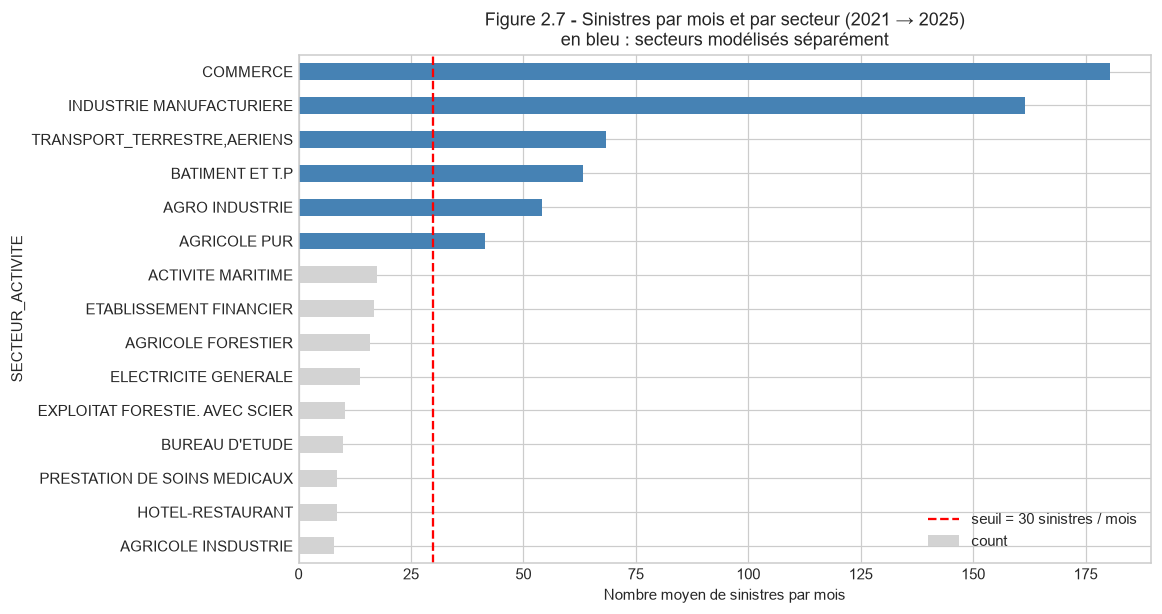

Secteurs modélisés séparément : ['COMMERCE', 'INDUSTRIE MANUFACTURIERE', 'TRANSPORT_TERRESTRE,AERIENS', 'BATIMENT ET T.P', 'AGRO INDUSTRIE', 'AGRICOLE PUR']
Ils représentent 79.4 % des sinistres récents.
Les 26 autres secteurs sont regroupés dans 'AUTRES SECTEURS'.


In [13]:
recents = sin[(sin["ANNEE_ACCIDENT"] >= 2021) & (sin["date"] <= "2025-12-01")]
par_mois = recents["SECTEUR_ACTIVITE"].value_counts() / recents["date"].nunique()

SEUIL = 30
secteurs = list(par_mois[par_mois >= SEUIL].index)

top15 = par_mois.head(15).sort_values()
top15.plot(kind="barh", figsize=(10, 6), color=["steelblue" if s in secteurs else "lightgrey" for s in top15.index])
plt.axvline(SEUIL, color="red", linestyle="--", label=f"seuil = {SEUIL} sinistres / mois")
plt.title("Figure 2.7 - Sinistres par mois et par secteur (2021 → 2025)\nen bleu : secteurs modélisés séparément")
plt.xlabel("Nombre moyen de sinistres par mois")
plt.legend()
plt.show()

print("Secteurs modélisés séparément :", secteurs)
print(f"Ils représentent {par_mois[secteurs].sum() / par_mois.sum() * 100:.1f} % des sinistres récents.")
print(f"Les {len(par_mois) - len(secteurs)} autres secteurs sont regroupés dans 'AUTRES SECTEURS'.")

**Commentaire - Figure 2.7 :** **6 secteurs** dépassent 30 sinistres par mois (commerce, industrie manufacturière, transport, BTP, agro-industrie, agricole pur). À eux six, ils couvrent environ **79 % des sinistres**. Les autres secteurs (chacun sous le seuil) sont regroupés dans **« AUTRES SECTEURS »**. Au total : **7 modèles sectoriels**, en plus du modèle national.

### 5.2 Les secteurs évoluent-ils ensemble ? (matrice de corrélation)

On construit la série mensuelle de chaque secteur, puis on calcule la **corrélation** entre les secteurs, deux à deux :
* proche de **+1** : les deux secteurs montent et descendent **ensemble** ;
* proche de **0** : ils évoluent **indépendamment**.

On calcule la corrélation sur les **variations d'une année sur l'autre** (même mois de l'année précédente). Sinon, la hausse générale depuis 2012 rendrait tous les secteurs artificiellement corrélés.

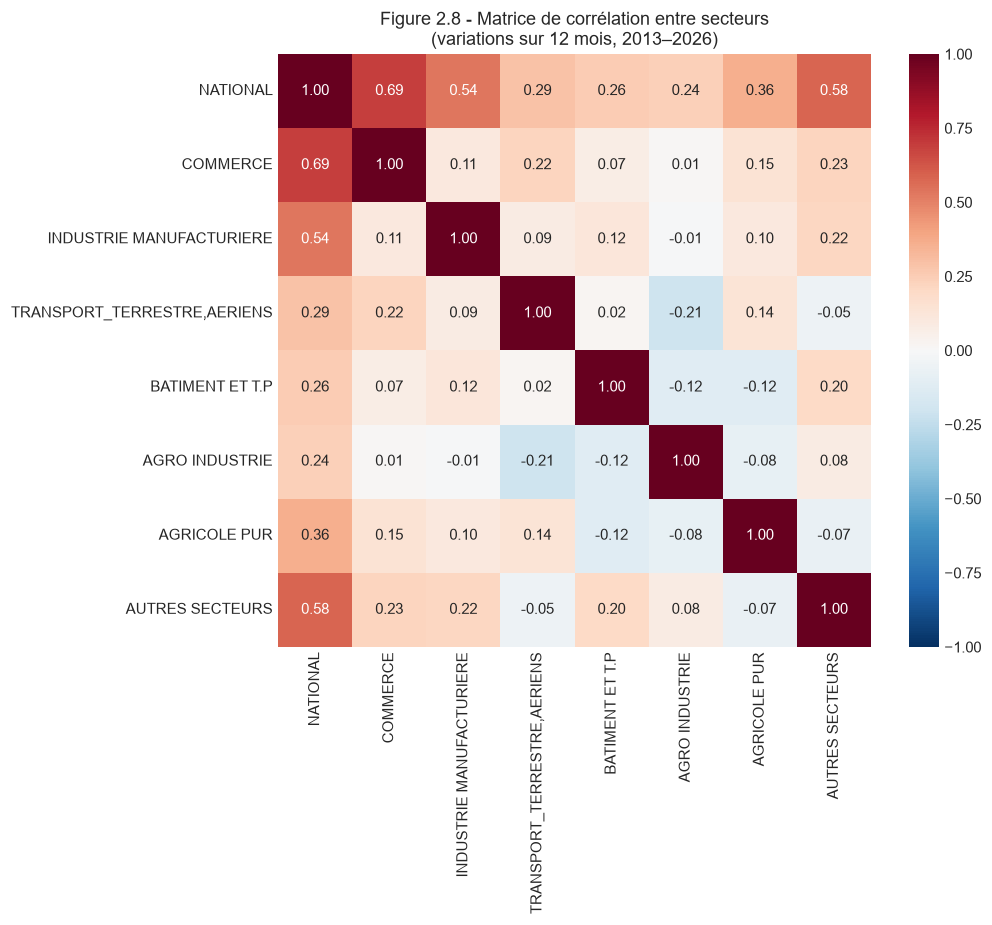

In [14]:
series = {"NATIONAL": serie}
for s in secteurs:
    series[s] = sin[sin["SECTEUR_ACTIVITE"] == s].groupby("date").size().reindex(serie.index, fill_value=0)
series["AUTRES SECTEURS"] = sin[~sin["SECTEUR_ACTIVITE"].isin(secteurs)].groupby("date").size().reindex(serie.index, fill_value=0)

table_series = pd.DataFrame(series)
variations = table_series.diff(12)            # variation par rapport au même mois de l'année précédente
correlation = variations.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Figure 2.8 - Matrice de corrélation entre secteurs\n(variations sur 12 mois, 2013–2026)")
plt.show()

**Commentaire - Figure 2.8 :**
* La **première ligne** (national) est surtout corrélée aux **gros secteurs** (commerce, industrie, autres secteurs) : ce sont eux qui portent le volume total.
* **Entre secteurs**, les corrélations sont **faibles** : chaque secteur suit **sa propre évolution**.
* **Conséquence :** on ne peut pas « découper » la prévision nationale avec des pourcentages fixes par secteur. Cela **justifie un modèle par secteur**, en cohérence avec le test H1 du notebook 1 (profil de risque différent selon le secteur).

### 5.3 Évaluation des modèles pour chaque secteur

Même protocole que pour le national : on **cache l'année 2025**, on entraîne les 3 modèles sur 2012→2024, puis on compare à la réalité 2025.

On ajoute une référence : le **bruit de Poisson**. Quand des événements rares arrivent au hasard (loi de Poisson), leur nombre varie naturellement d'environ **100 / √(moyenne mensuelle) %** d'un mois à l'autre. **Aucun modèle ne peut descendre durablement sous ce niveau** : c'est la part de hasard irréductible.

In [15]:
def predire_12_mois(train):
    """Prévisions des 3 modèles pour les 12 mois qui suivent la série d'entraînement."""
    mois_futurs = pd.date_range(train.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")
    naif = pd.Series(train[-12:].values, index=mois_futurs)
    sarima = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False).forecast(12)
    p = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    p.fit(pd.DataFrame({"ds": train.index, "y": train.values}))
    prophet = pd.Series(p.predict(pd.DataFrame({"ds": mois_futurs}))["yhat"].values, index=mois_futurs)
    return {"Naïf saisonnier": naif, "SARIMA": sarima, "Prophet": prophet}

def calculer_metriques(reel, prevu):
    erreur = reel - prevu
    return {"MAE": np.mean(np.abs(erreur)),
            "RMSE": np.sqrt(np.mean(erreur ** 2)),
            "MAPE (%)": np.mean(np.abs(erreur) / reel) * 100,
            "Écart annuel (%)": (prevu.sum() - reel.sum()) / reel.sum() * 100}

metriques = []
erreurs_sarima = {}
for nom, s in series.items():
    train, test = s[:-12], s[-12:]
    for modele, prevu in predire_12_mois(train).items():
        metriques.append({"Série": nom, "Modèle": modele, "Moyenne / mois": test.mean(),
                          "Bruit de Poisson (%)": 100 / np.sqrt(test.mean()), **calculer_metriques(test, prevu)})
        if modele == "SARIMA":
            erreurs_sarima[nom] = (prevu - test) / test * 100

metriques = pd.DataFrame(metriques)
metriques.round(1)

,Série,Modèle,Moyenne / mois,Bruit de Poisson (%),MAE,RMSE,MAPE (%),Écart annuel (%)
0,NATIONAL,Naïf saisonnier,724.0,3.7,52.8,59.6,7.4,2.4
1,NATIONAL,SARIMA,724.0,3.7,49.7,62.3,7.1,5.0
2,NATIONAL,Prophet,724.0,3.7,47.9,61.6,6.9,4.7
3,COMMERCE,Naïf saisonnier,185.9,7.3,14.6,19.0,8.0,-0.5
4,COMMERCE,SARIMA,185.9,7.3,15.0,20.7,8.4,4.1
5,COMMERCE,Prophet,185.9,7.3,14.2,21.3,7.7,0.7
6,INDUSTRIE MANUFACTURIERE,Naïf saisonnier,175.2,7.6,23.6,28.6,13.7,6.0
7,INDUSTRIE MANUFACTURIERE,SARIMA,175.2,7.6,21.3,24.4,12.8,10.5
8,INDUSTRIE MANUFACTURIERE,Prophet,175.2,7.6,14.8,18.6,8.9,6.2
9,"TRANSPORT_TERRESTRE,AERIENS",Naïf saisonnier,58.2,13.1,8.4,9.9,15.2,6.4


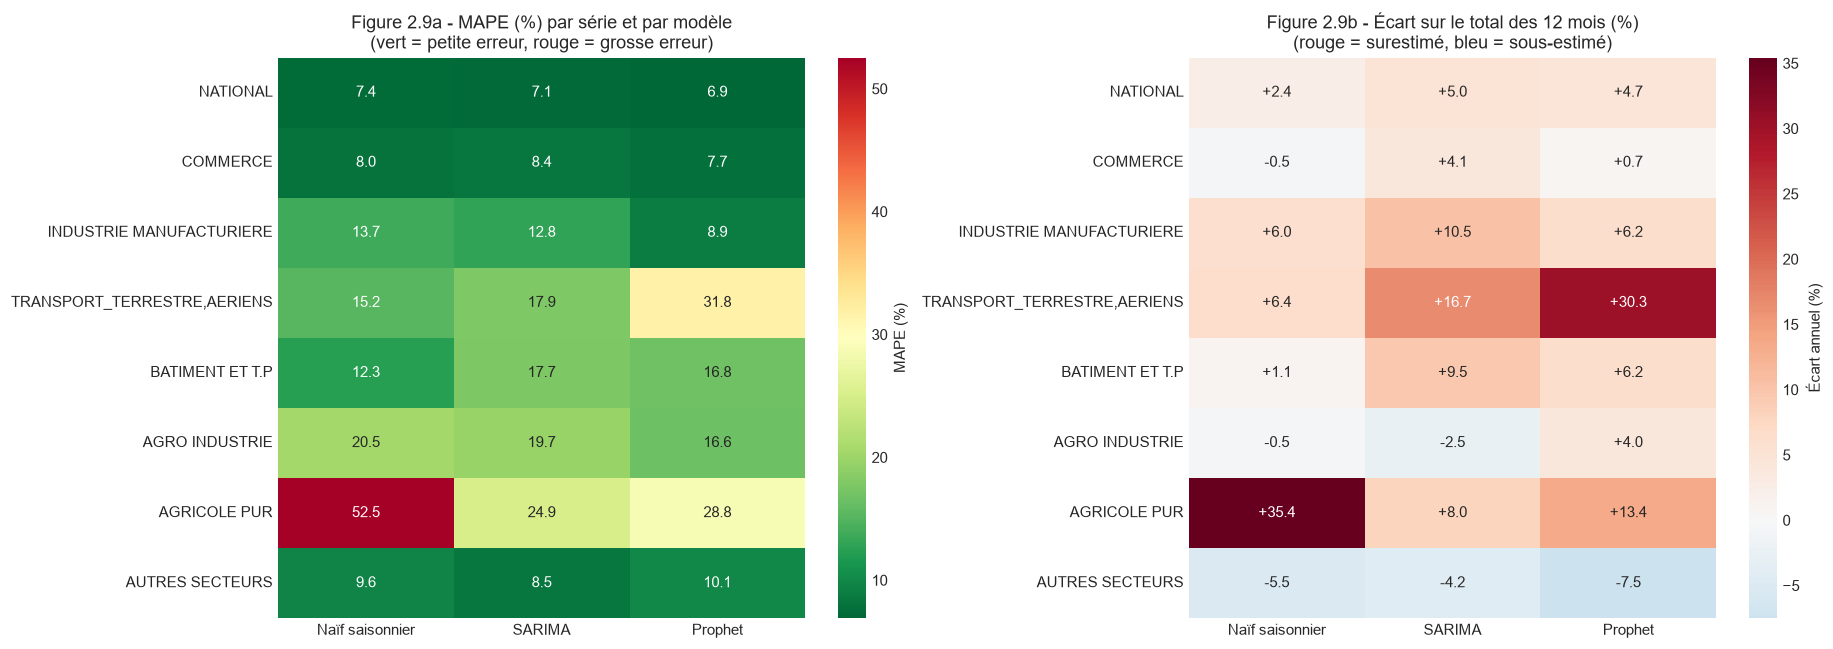

Meilleur modèle pour chaque série :


,Modèle,MAPE (%)
Série,,
NATIONAL,Prophet,6.9
COMMERCE,Prophet,7.7
INDUSTRIE MANUFACTURIERE,Prophet,8.9
"TRANSPORT_TERRESTRE,AERIENS",Naïf saisonnier,15.2
BATIMENT ET T.P,Naïf saisonnier,12.3
AGRO INDUSTRIE,Prophet,16.6
AGRICOLE PUR,SARIMA,24.9
AUTRES SECTEURS,SARIMA,8.5


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ordre = list(series)

mape = metriques.pivot(index="Série", columns="Modèle", values="MAPE (%)").loc[ordre, ["Naïf saisonnier", "SARIMA", "Prophet"]]
sns.heatmap(mape, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axes[0], cbar_kws={"label": "MAPE (%)"})
axes[0].set_title("Figure 2.9a - MAPE (%) par série et par modèle\n(vert = petite erreur, rouge = grosse erreur)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

ecart = metriques.pivot(index="Série", columns="Modèle", values="Écart annuel (%)").loc[ordre, ["Naïf saisonnier", "SARIMA", "Prophet"]]
sns.heatmap(ecart, annot=True, fmt="+.1f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "Écart annuel (%)"})
axes[1].set_title("Figure 2.9b - Écart sur le total des 12 mois (%)\n(rouge = surestimé, bleu = sous-estimé)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

meilleur = metriques.loc[metriques.groupby("Série")["MAPE (%)"].idxmin(), ["Série", "Modèle", "MAPE (%)"]].set_index("Série").loc[ordre]
print("Meilleur modèle pour chaque série :")
meilleur.round(1)

**Commentaire - Figures 2.9a et 2.9b :**
* **Gros secteurs** (commerce, industrie, autres) : erreur proche de celle du national (voir heatmap).
* **Il n'y a pas de modèle gagnant partout** : selon le secteur, c'est SARIMA, Prophet ou même le naïf qui minimise la MAPE sur 2025.
* **Prophet peut déraper** sur un petit secteur (il prolonge une tendance qui s'arrête), alors que **SARIMA n'a jamais d'erreur catastrophique**. C'est cette **robustesse**, et son **intervalle de confiance**, qui le font retenir pour toutes les prévisions finales.
* Les **petits secteurs** (agro-industrie, agricole pur) ont les plus grosses erreurs relatives : c'est principalement du **bruit de Poisson** (section suivante), pas un défaut de modèle.

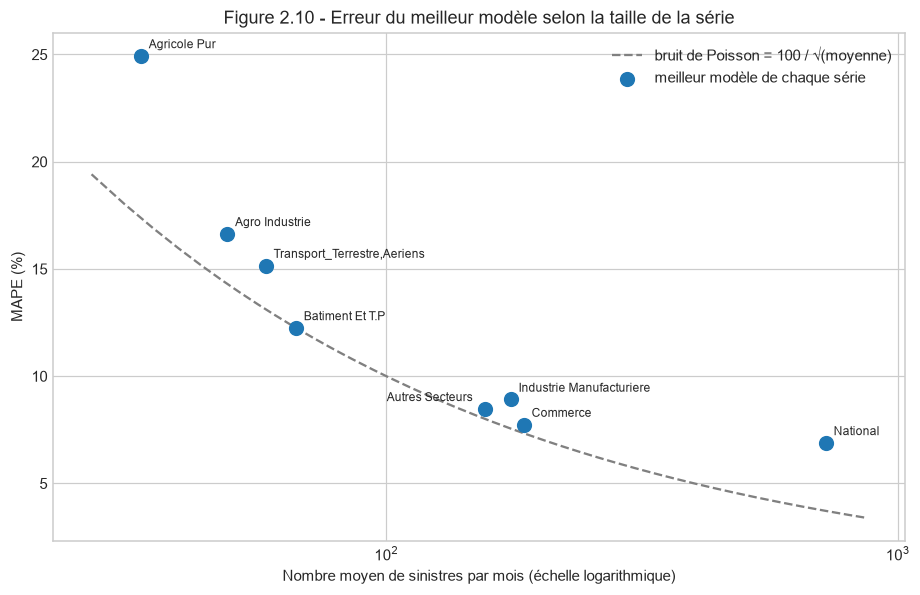

In [17]:
meilleure_mape = metriques.groupby("Série")["MAPE (%)"].min()
volume = metriques.groupby("Série")["Moyenne / mois"].first()

plt.figure(figsize=(10, 6))
x = np.linspace(volume.min() * 0.8, volume.max() * 1.2, 200)
plt.plot(x, 100 / np.sqrt(x), "--", color="grey", label="bruit de Poisson = 100 / √(moyenne)")
plt.scatter(volume, meilleure_mape, s=80, color="tab:blue", zorder=3, label="meilleur modèle de chaque série")
for nom in volume.index:
    a_gauche = nom == "AUTRES SECTEURS"                              # étiquette à gauche pour éviter un chevauchement
    plt.annotate(nom.title(), (volume[nom], meilleure_mape[nom]), fontsize=8, textcoords="offset points",
                 xytext=(-8, 5) if a_gauche else (5, 5), ha="right" if a_gauche else "left")
plt.xscale("log")
plt.title("Figure 2.10 - Erreur du meilleur modèle selon la taille de la série")
plt.xlabel("Nombre moyen de sinistres par mois (échelle logarithmique)")
plt.ylabel("MAPE (%)")
plt.legend()
plt.show()

**Commentaire - Figure 2.10 :**
* L'erreur **baisse quand le volume augmente**, et les points suivent la **courbe du bruit de Poisson** (100/√moyenne). Plus un secteur a de sinistres, plus sa prévision est précise.
* La plupart des points sont **juste au-dessus de la courbe** : les modèles sont **proches de la meilleure précision possible**. Pour les petits secteurs, l'erreur vient surtout du **hasard**.
* C'est au **niveau national** qu'il reste le plus de marge (ajouter des variables explicatives : activité économique, jours ouvrés, effet crise).

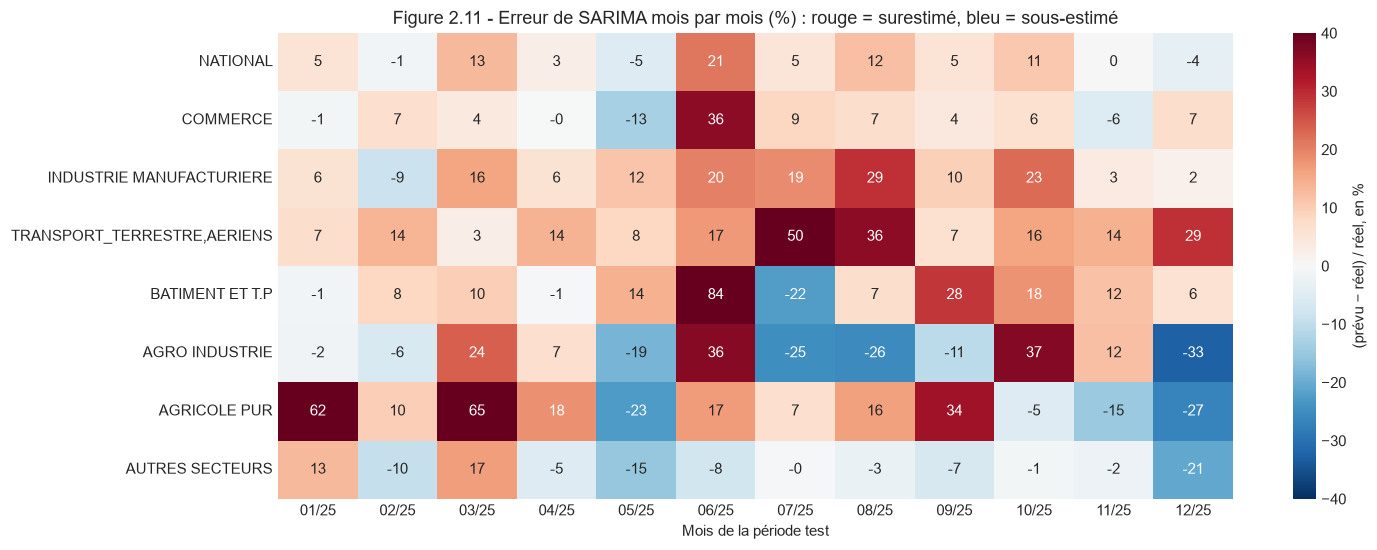

In [18]:
matrice_erreurs = pd.DataFrame(erreurs_sarima).T.loc[ordre]
matrice_erreurs.columns = matrice_erreurs.columns.strftime("%m/%y")

plt.figure(figsize=(14, 5.5))
sns.heatmap(matrice_erreurs, annot=True, fmt=".0f", cmap="RdBu_r", center=0, vmin=-40, vmax=40,
            cbar_kws={"label": "(prévu − réel) / réel, en %"})
plt.title("Figure 2.11 - Erreur de SARIMA mois par mois (%) : rouge = surestimé, bleu = sous-estimé")
plt.xlabel("Mois de la période test")
plt.ylabel("")
plt.show()

**Commentaire - Figure 2.11 :** cette matrice montre **où et quand** le modèle se trompe sur l'année de test 2025.
* Une colonne entièrement **bleue ou rouge** signale un mois où presque tous les secteurs sont mal prévus en même temps : c'est le signe d'un **effet global** (et non propre à un secteur).
* Une ligne majoritairement d'une seule couleur signale un **secteur systématiquement sur- ou sous-estimé** : il a changé de régime et son modèle **doit être ré-entraîné** avec les données récentes.
* Les secteurs les plus irréguliers (BTP, agro-industrie, agricole pur) alternent fortement : leur faible volume les rend sensibles au hasard.

### 5.4 Prévision de l'année 2026 par secteur

Chaque modèle SARIMA sectoriel est ré-entraîné sur toutes les données ≤ 2025, puis **sauvegardé** dans `modeles/`. On vérifie la **cohérence** : la **somme des prévisions sectorielles** (approche « par le bas ») doit être proche de la **prévision nationale** (approche « par le haut »).

In [19]:
import joblib

previsions = {}
resume = []
for nom in ordre[1:]:                         # tous les secteurs (sans le national)
    s = series[nom]
    modele = SARIMAX(s, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
    prevision = modele.get_forecast(12)
    previsions[nom] = (s, prevision.predicted_mean, prevision.conf_int())

    nom_fichier = nom.lower().replace(" ", "_").replace(",", "_").replace(".", "")
    joblib.dump(modele, f"modeles/macro_sarima_secteur_{nom_fichier}.joblib")

    resume.append({"Secteur": nom, "Réel 2025": int(s[-12:].sum()),
                   "Prévu 2026": round(prevision.predicted_mean.sum())})

resume = pd.DataFrame(resume).set_index("Secteur")
resume["Évolution (%)"] = ((resume["Prévu 2026"] / resume["Réel 2025"] - 1) * 100).round(1)
resume.loc["SOMME DES SECTEURS"] = [resume["Réel 2025"].sum(), resume["Prévu 2026"].sum(),
                                    round((resume["Prévu 2026"].sum() / resume["Réel 2025"].sum() - 1) * 100, 1)]
resume.loc["MODÈLE NATIONAL"] = [totaux["National"]["Réel 2025"], totaux["National"]["Prévu 2026"],
                                 round((totaux["National"]["Prévu 2026"] / totaux["National"]["Réel 2025"] - 1) * 100, 1)]
print(f"{len(previsions)} modèles sectoriels sauvegardés dans modeles/")
resume

7 modèles sectoriels sauvegardés dans modeles/


,Réel 2025,Prévu 2026,Évolution (%)
Secteur,,,
COMMERCE,2231.0,2320.0,4.0
INDUSTRIE MANUFACTURIERE,2103.0,2151.0,2.3
"TRANSPORT_TERRESTRE,AERIENS",698.0,702.0,0.6
BATIMENT ET T.P,800.0,812.0,1.5
AGRO INDUSTRIE,587.0,586.0,-0.2
AGRICOLE PUR,398.0,441.0,10.8
AUTRES SECTEURS,1871.0,1924.0,2.8
SOMME DES SECTEURS,8688.0,8936.0,2.9
MODÈLE NATIONAL,8688.0,8961.0,3.1


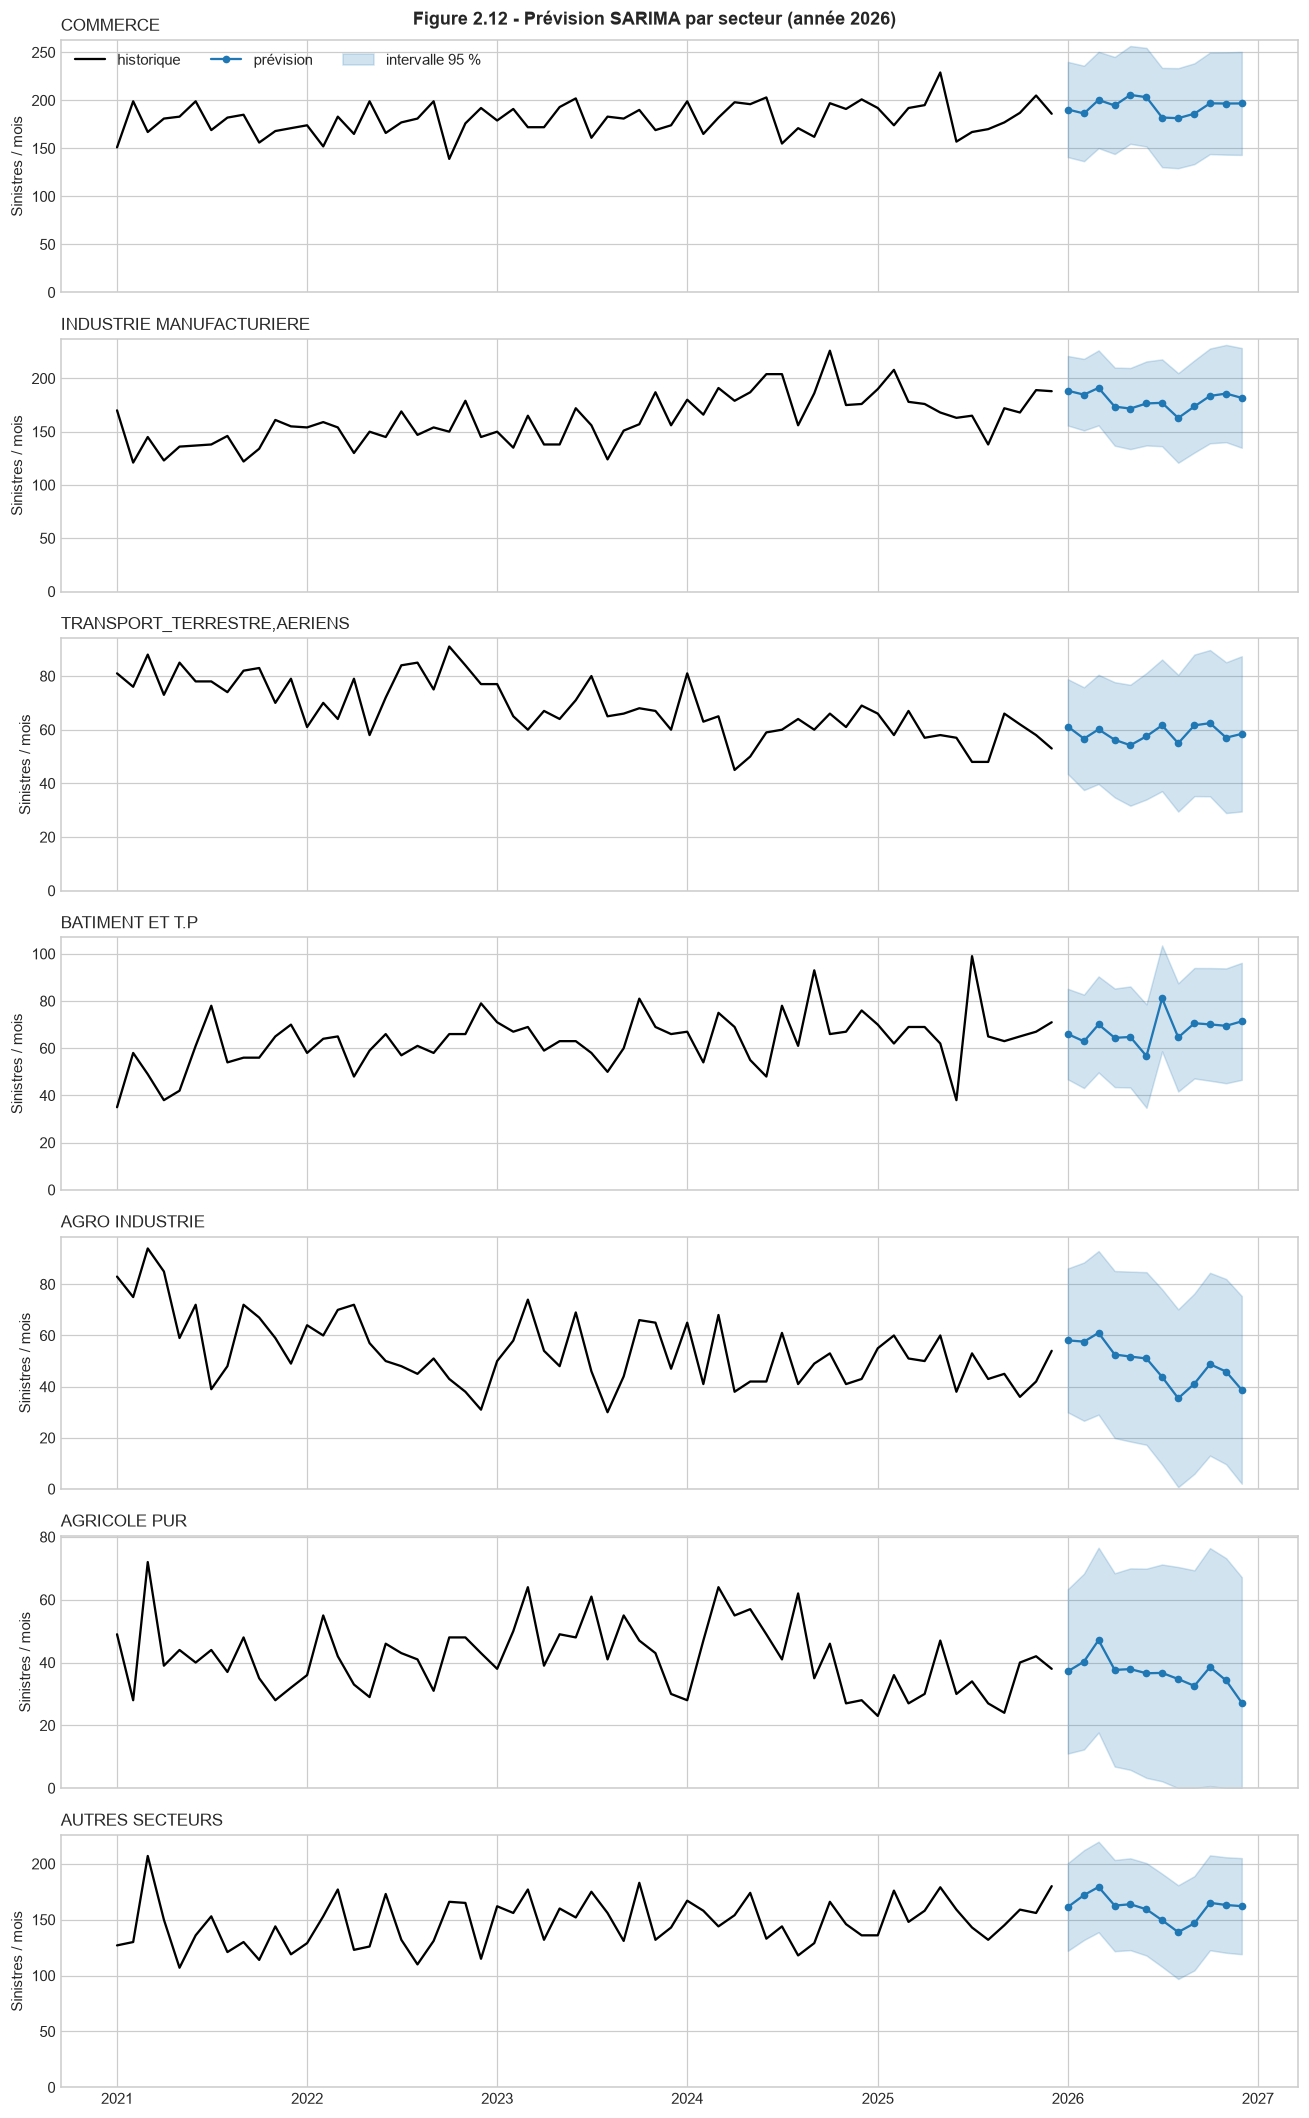

In [20]:
fig, axes = plt.subplots(len(previsions), 1, figsize=(12, 2.8 * len(previsions)), sharex=True)
for ax, (nom, (s, prevision, intervalle)) in zip(axes, previsions.items()):
    ax.plot(s["2021":], color="black", label="historique")
    ax.plot(prevision, color="tab:blue", marker="o", markersize=4, label="prévision")
    ax.fill_between(intervalle.index, intervalle.iloc[:, 0].clip(lower=0), intervalle.iloc[:, 1], color="tab:blue", alpha=0.2, label="intervalle 95 %")
    ax.set_title(nom, loc="left", fontsize=11)
    ax.set_ylabel("Sinistres / mois")
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper left", ncol=3)
fig.suptitle("Figure 2.12 - Prévision SARIMA par secteur (année 2026)", fontweight="bold")
plt.tight_layout()
plt.show()

**Commentaire - Tableau et Figure 2.12 :**
* Le tableau donne, pour chaque secteur, le réel 2025 et la **prévision 2026**, avec l'évolution attendue.
* **Cohérence des deux approches :** la **somme des prévisions sectorielles** (par le bas) et la **prévision nationale** (par le haut) sont proches - l'écart figure sur les deux dernières lignes du tableau. Deux chemins de calcul indépendants qui **concordent** renforcent la confiance dans la prévision.
* Les **intervalles de confiance** sont larges pour les petits secteurs : pour eux, on raisonne sur le **total annuel** plutôt que mois par mois.
* Les **7 modèles sectoriels** sont sauvegardés dans `modeles/macro_sarima_secteur_*.joblib`.

**Conclusion de l'analyse par secteur :** même méthode, un modèle par secteur. Bonne précision pour les gros secteurs, limitée par le hasard pour les petits, et prévisions sectorielles cohérentes avec le national.

## 6. Sauvegarde des modèles national et BTP

Les deux modèles SARIMA finaux (national et BTP) sont enregistrés dans `modeles/`. On peut les recharger pour produire une nouvelle prévision sans tout ré-entraîner.

In [21]:
import joblib

joblib.dump(modeles_finaux["National"], "modeles/macro_sarima_national.joblib")
joblib.dump(modeles_finaux["BTP"], "modeles/macro_sarima_btp.joblib")
print("Modèles sauvegardés dans modeles/")

# Exemple de rechargement
modele_charge = joblib.load("modeles/macro_sarima_national.joblib")
print("Prévision des 3 prochains mois (national) :")
print(modele_charge.forecast(3).round(0))

Modèles sauvegardés dans modeles/
Prévision des 3 prochains mois (national) :
2026-01-01    748.0
2026-02-01    765.0
2026-03-01    806.0
Freq: MS, Name: predicted_mean, dtype: float64
